<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [LightGBM](https://github.com/vgi-lightgbm)

Train, tune, evaluate, and explain gradient-boosted classifiers and regressors, with a saved-model registry.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vgi-lightgbm/blob/main/notebooks/02_gain_shuffling_and_average_response.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/vgi-lightgbm/blob/main/notebooks/README.md)


## Do model gain, shuffle loss and average response tell the same story?

Generate a fixed synthetic regression sample, train one model, and compare three different interpretations. Split gain describes the fitted tree construction; permutation importance measures prediction loss when an evaluation feature is shuffled; partial dependence averages model responses after replacing one feature. Their numbers have different units and none establishes causality.

A constant-zero feature is deliberately retained as a control. The seed fixes the generated sample, but the generator’s two informative-feature coefficients are not returned; do not infer a true coefficient or feature identity from a model ranking. These are arbitrary generated feature/target units, not observed scientific measurements.

In [1]:
EVALUATION_SPLIT = "heldout"  # Experiment: "training"; model and generated sample remain fixed

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.52":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.52"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, theme, prose, prepare
from IPython.display import display
from pathlib import Path
import os, tempfile

check_runtime()
prepare("lightgbm")
import lightgbm_example as example

registry = tempfile.TemporaryDirectory(prefix="lightgbm-example-")
previous_registry = os.environ.get("LIGHTGBM_MODELS_DIR")
os.environ["LIGHTGBM_MODELS_DIR"] = registry.name
session = connect(globals())
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
theme()
assert EVALUATION_SPLIT in ("heldout","training")

### Start the published release in an isolated registry

The release wheel includes implementation modules but omits its top-level worker entry file and console command. The small **worker-specific** companion verifies the installed Git revision and retrieves only that unchanged file from the fixed public release commit, with SHA256 verification and an atomic cache. It accepts no URL, revision or command arguments. The visible release tag owns dependencies; no overrides or local worker checkout are used. First use requires public package/file access and the platform OpenMP runtime.

Every run creates a new temporary model registry before attachment. Named models and deletion below belong only to this run; no existing model directory or persistent SQL credentials is opened.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'lightgbm' (TYPE vgi, LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-lightgbm@v0.1.0 python lightgbm_release.py');

,Success


### Generate once, then fix the split

The worker generates **600 rows**, three numeric features and a continuous target with two informative terms plus noise standard deviation 5, using seed 42. IDs divisible by four are reserved: 150 held-out rows versus 450 training rows. Add a constant-zero control in SQL. Materialization prevents regenerated input during repeated display or model fitting.

In [5]:
%%sql
CREATE TABLE generated AS SELECT * FROM lightgbm.main.make_regression(n_samples:=600,n_features:=3,n_informative:=2,noise:=5.0,random_state:=42);
CREATE TABLE samples AS SELECT *,0.0::DOUBLE AS constant_zero,CASE WHEN sample_id%4=0 THEN 'heldout' ELSE 'training' END AS sample_role FROM generated;
SELECT sample_role,count(*) AS rows,min(sample_id) AS first_id,max(sample_id) AS last_id FROM samples GROUP BY sample_role ORDER BY sample_role;

,sample_role,rows,first_id,last_id
0,heldout,150,0,596
1,training,450,1,599


### Fit the same typed regressor in both runs

The typed function exposes the estimator settings explicitly. Only feature_0, feature_1, feature_2 and constant_zero enter training; sample_id and target are identified separately. Fit receives training rows only. The release defaults use one thread and suppress training progress. The named model belongs to this run’s empty temporary registry.

In [6]:
%%sql
CREATE TABLE fitted AS SELECT * FROM lightgbm.main.fit_lgbm_regressor(
 (SELECT sample_id,feature_0,feature_1,feature_2,constant_zero,target FROM samples WHERE sample_role='training' ORDER BY sample_id),
 model_name:='interpretation',target:='target',id:='sample_id',n_estimators:=60,num_leaves:=15,min_child_samples:=10,learning_rate:=0.1,random_state:=13);
SELECT model_name,n_samples,n_features,features,octet_length(model) AS model_bytes FROM fitted;
CREATE TABLE evaluation AS SELECT sample_id,feature_0,feature_1,feature_2,constant_zero,target FROM samples WHERE sample_role='{{EVALUATION_SPLIT}}';
CREATE TABLE all_predictions AS SELECT * FROM lightgbm.main.predict((SELECT sample_id,feature_0,feature_1,feature_2,constant_zero FROM samples ORDER BY sample_id),model_name:='interpretation',id:='sample_id');
CREATE TABLE predicted AS SELECT p.* FROM all_predictions p JOIN evaluation e USING(sample_id);
CREATE TABLE errors AS SELECT e.*,p.prediction,p.prediction-e.target AS residual FROM evaluation e JOIN predicted p USING(sample_id);

,Count


In [7]:
%%sql performance <<
SELECT count(*) AS evaluated_rows,avg(abs(residual)) AS mae,sqrt(avg(residual*residual)) AS rmse FROM errors;

In [8]:
display(performance)
prose(f"The **{EVALUATION_SPLIT}** population contains **{int(performance.evaluated_rows.iloc[0])} rows**, with MAE **{performance.mae.iloc[0]:.4f} target units**. Training diagnostics are not held-out performance. The next comparisons use this same selected population and the unchanged fitted model.")

,evaluated_rows,mae,rmse
0,150,8.432199,10.975738


The **heldout** population contains **150 rows**, with MAE **8.4322 target units**. Training diagnostics are not held-out performance. The next comparisons use this same selected population and the unchanged fitted model.

### Compare measurements with different denominators

Gain sums training split improvements inside the fitted model. Permutation uses **negative mean absolute error** as its scorer; a decrease in that score therefore equals an **increase in MAE**, in target units. Negative importance is possible if shuffling improves this sample’s predictions. Five repeated shuffles use seed 7; error bars are their standard deviation, not a confidence interval. Keep all four features, including the zero control.

In [9]:
%%sql
CREATE TABLE gains AS SELECT * FROM lightgbm.main.feature_importance('interpretation',importance_type:='gain');
CREATE TABLE permutations AS SELECT * FROM lightgbm.main.permutation_importance((SELECT * FROM evaluation ORDER BY sample_id),model_name:='interpretation',target:='target',n_repeats:=5,scoring:='neg_mean_absolute_error',random_state:=7);
CREATE TABLE importance_comparison AS SELECT g.feature,g.importance AS split_gain,g.rank AS gain_rank,p.importance_mean AS mae_increase,p.importance_std AS shuffle_std,p.rank AS permutation_rank FROM gains g JOIN permutations p USING(feature);

,Count


In [10]:
%%sql importance <<
SELECT * FROM importance_comparison ORDER BY feature;

,feature,split_gain,gain_rank,mae_increase,shuffle_std,permutation_rank
0,constant_zero,0.000000e+00,4,0.000000,0.000000,4
1,feature_0,1.109780e+07,1,79.981490,2.849716,1
2,feature_1,2.536890e+04,3,0.033405,0.094427,3
3,feature_2,5.012570e+06,2,41.467544,2.467740,2


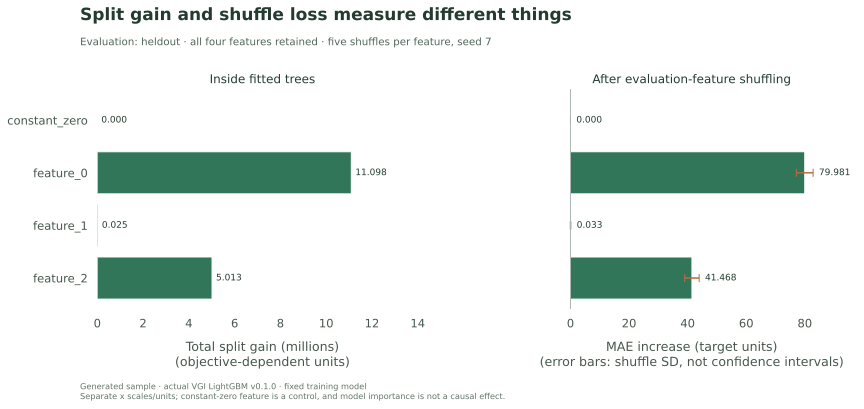

The constant control has **0.0000 gain** and **0.0000 MAE increase**. That arithmetic check is useful; it does not make the other scores causal effects or comparable across different models/scorers.

In [11]:
display(importance)
example.importances(importance,EVALUATION_SPLIT)
control=importance[importance.feature=="constant_zero"].iloc[0]
prose(f"The constant control has **{control.split_gain:.4f} gain** and **{control.mae_increase:.4f} MAE increase**. That arithmetic check is useful; it does not make the other scores causal effects or comparable across different models/scorers.")

### Read partial dependence as model averaging

For feature_0, replace that feature at a returned grid value across the selected background rows, leave other features unchanged, predict, and average. The curve is an artificial model query; it does not hold real-world causes fixed. Its grid follows the selected background, so changing evaluation split can change grid locations as well as averages. Separately reconstruct the middle grid value with actual prediction calls to check this interpretation.

In [12]:
%%sql
CREATE TABLE partial_curve AS SELECT * FROM lightgbm.main.partial_dependence((SELECT feature_0,feature_1,feature_2,constant_zero FROM evaluation ORDER BY sample_id),model_name:='interpretation',feature:='feature_0',grid_resolution:=17);
CREATE TABLE middle_grid AS SELECT feature_value,partial_dependence FROM (SELECT *,row_number() OVER(ORDER BY feature_value) rn,count(*) OVER() n FROM partial_curve) WHERE rn=ceil(n/2.0);
CREATE TABLE changed_background AS SELECT e.sample_id,m.feature_value AS feature_0,e.feature_1,e.feature_2,e.constant_zero FROM evaluation e CROSS JOIN middle_grid m;
CREATE TABLE recomputed AS SELECT * FROM lightgbm.main.predict((SELECT * FROM changed_background ORDER BY sample_id),model_name:='interpretation',id:='sample_id');
CREATE TABLE pd_check AS SELECT (SELECT avg(prediction) FROM recomputed) AS independent_mean,(SELECT partial_dependence FROM middle_grid) AS returned_mean;

,Count


In [13]:
%%sql pd_frame <<
SELECT * FROM partial_curve ORDER BY feature_value;

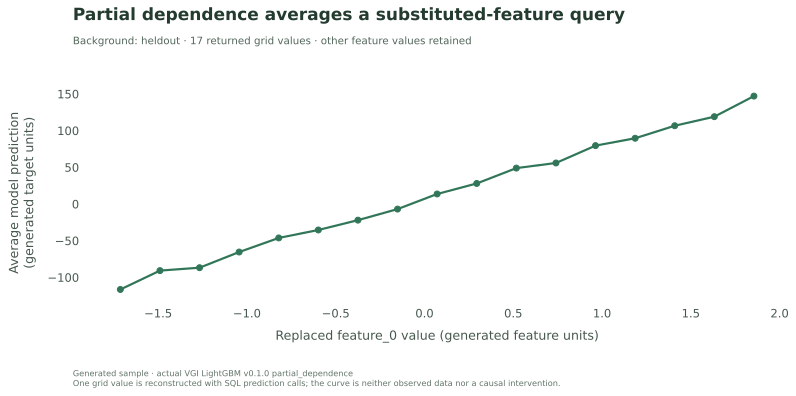

,independent_mean,returned_mean
0,13.643346,13.643346


The worker returned **17 grid values**. At the middle grid value, replacing feature_0 and averaging actual model predictions reproduces the returned partial dependence. This verifies model averaging for this point, not the generated process or an intervention effect.

In [14]:
example.partial_response(pd_frame,EVALUATION_SPLIT)
display(con.execute("SELECT * FROM pd_check").df())
prose(f"The worker returned **{len(pd_frame)} grid values**. At the middle grid value, replacing feature_0 and averaging actual model predictions reproduces the returned partial dependence. This verifies model averaging for this point, not the generated process or an intervention effect.")
export=Path("artifacts/data/02");export.mkdir(parents=True,exist_ok=True)
importance.to_csv(export/"importance.csv",index=False);pd_frame.to_csv(export/"partial.csv",index=False);performance.to_csv(export/"performance.csv",index=False)
con.execute("SELECT * FROM samples ORDER BY sample_id").df().to_csv(export/"samples.csv",index=False)
con.execute("SELECT sample_id,prediction,target,residual FROM errors ORDER BY sample_id").df().to_csv(export/"predictions.csv",index=False)
con.execute("SELECT n_samples,n_features,features FROM fitted").df().to_csv(export/"model.csv",index=False)
con.execute("SELECT * FROM all_predictions ORDER BY sample_id").df().to_csv(export/"all_predictions.csv",index=False)

### Audit rows, feature scope and a reconstructed average

The tests retain every named feature and selected evaluation row, keep the constant feature at zero importance, and verify the partial-dependence reconstruction. No assertion requires a winning feature rank, positive permutation importance for every feature, or a particular accuracy score.

In [15]:
%%sql checks <<
SELECT '600 unique generated samples' AS check_name,(SELECT count(*)=600 AND count(DISTINCT sample_id)=600 FROM samples) AS passed
UNION ALL SELECT 'fixed450/150split',(SELECT count(*) FILTER(WHERE sample_role='training')=450 AND count(*) FILTER(WHERE sample_role='heldout')=150 FROM samples)
UNION ALL SELECT 'fit uses450rows and fourfeatures',(SELECT count(*)=1 AND min(n_samples)=450 AND min(n_features)=4 AND min(features)=['feature_0','feature_1','feature_2','constant_zero'] FROM fitted)
UNION ALL SELECT 'one prediction per selected ID',(SELECT count(*)=count(DISTINCT sample_id) AND count(*)=(SELECT count(*) FROM evaluation) FROM predicted)
UNION ALL SELECT 'no missing selected predictions',(SELECT count(*)=0 FROM (SELECT sample_id FROM evaluation EXCEPT SELECT sample_id FROM predicted))
UNION ALL SELECT 'four complete feature rows',(SELECT count(*)=4 AND count(DISTINCT feature)=4 FROM importance_comparison)
UNION ALL SELECT 'finite importance values',(SELECT bool_and(isfinite(split_gain) AND isfinite(mae_increase) AND shuffle_std>=0) FROM importance_comparison)
UNION ALL SELECT 'constant control has zero impact',(SELECT split_gain=0 AND abs(mae_increase)<1e-10 AND shuffle_std<1e-10 FROM importance_comparison WHERE feature='constant_zero')
UNION ALL SELECT 'regression grid17uniquevalues',(SELECT count(*)=17 AND count(DISTINCT feature_value)=17 AND count(class)=0 FROM partial_curve)
UNION ALL SELECT 'partial dependence mean reconstructs',(SELECT abs(independent_mean-returned_mean)<1e-8 FROM pd_check)
UNION ALL SELECT 'reconstruction preserves background size',(SELECT count(*)=(SELECT count(*) FROM evaluation) FROM recomputed)
UNION ALL SELECT 'finite losses and RMSE boundsMAE',(SELECT bool_and(isfinite(residual)) AND sqrt(avg(residual*residual))+1e-10>=avg(abs(residual)) FROM errors);

In [16]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all()
prose(f"**{len(checks)} SQL checks passed.**")

,check_name,passed
0,600 unique generated samples,True
1,fixed450/150split,True
2,fit uses450rows and fourfeatures,True
3,one prediction per selected ID,True
4,no missing selected predictions,True
5,four complete feature rows,True
6,finite importance values,True
7,constant control has zero impact,True
8,regression grid17uniquevalues,True
9,partial dependence mean reconstructs,True


**12 SQL checks passed.**

### Focused experiment: change the evaluation population

Change only **`EVALUATION_SPLIT` from heldout to training**. Generated rows, training data, fitted model and split-gain values must remain fixed. Permutation loss and partial dependence now summarize a different population; compare them without treating the training result as an independent performance estimate. The selected sample grows from 150 to 450, so its shuffle variation is not directly a common-sample uncertainty interval. Temporary registry cleanup still removes only this run’s model.

In [17]:
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
session.close()
registry.cleanup()
if previous_registry is None:
    os.environ.pop("LIGHTGBM_MODELS_DIR",None)
else:
    os.environ["LIGHTGBM_MODELS_DIR"] = previous_registry

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-lightgbm](https://github.com/vgi-lightgbm)
